# Millionær-profil – Analyse og modellsammenligning
Datasett: Millionaire_Habits_Dataset.csv (syntetisk, Kaggle)  
Label: `millionaire_status` (1 hvis netto formue ≥ 1 000 000 USD)

## 0. Oppsett
Last inn data, velg features og lag train/test-splitt. Alle seksjoner under bruker de samme variablene.

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score

# Last inn data
df = pd.read_csv('archive/Millionaire_Habits_Dataset.csv')

FEATURES = ['age', 'total_annual_income', 'savings_rate']
TARGET   = 'millionaire_status'

df_model = df[FEATURES + [TARGET]].dropna()

X = df_model[FEATURES]
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f'Treningssett: {len(X_train):,} rader')
print(f'Testsett:     {len(X_test):,} rader')
print(f'Andel millionærer: {y.mean():.1%}')

Treningssett: 80,000 rader
Testsett:     20,000 rader
Andel millionærer: 42.5%


## 1. Baseline

Før vi trener noe som helst lager vi en enkel målestokk å sammenligne mot.  
`DummyClassifier` gjetter alltid den vanligste klassen, som her er "ikke millionær" siden det er 57,5 % av dataene.  
En ekte modell må gjøre det bedre enn dette, ellers har den ikke lært noe.

In [39]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_test)
y_prob_dummy = dummy.predict_proba(X_test)[:, 1]

print('--- Baseline (alltid gjett «ikke millionær») ---')
print(f'Accuracy: {accuracy_score(y_test, y_pred_dummy):.4f}')
print(f'AUC:      {roc_auc_score(y_test, y_prob_dummy):.4f}')
print()
print('Accuracy på 57,5 % kan se greit ut, men modellen har aldri')
print('predikert «millionær» – AUC på 0.50 bekrefter det.')

--- Baseline (alltid gjett «ikke millionær») ---
Accuracy: 0.5751
AUC:      0.5000

Accuracy på 57,5 % kan se greit ut, men modellen har aldri
predikert «millionær» – AUC på 0.50 bekrefter det.


## 2. Tre modeller sammenlignet

Vi tester tre modeller på de samme dataene og sammenligner resultatene:

- **Logistisk regresjon** – enkel lineær modell
- **Random Forest** – mange beslutningstrær kombinert
- **LightGBM** – bygger trær sekvensielt der hvert tre retter opp feilene til forrige

Alle trenes på `X_train` og evalueres på `X_test`.

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

def evaluer(navn, modell):
    modell.fit(X_train, y_train)
    y_pred = modell.predict(X_test)
    y_prob = modell.predict_proba(X_test)[:, 1]
    return {
        'Modell':     navn,
        'AUC':        round(roc_auc_score(y_test, y_prob), 4),
        'F1':         round(f1_score(y_test, y_pred), 4),
        'Precision':  round(precision_score(y_test, y_pred), 4),
        'Recall':     round(recall_score(y_test, y_pred), 4),
        'Accuracy':   round(accuracy_score(y_test, y_pred), 4),
    }

modeller = [
    ('Logistisk regresjon', Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=42)),
    ])),
    ('Random Forest', Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ])),
    ('LightGBM', Pipeline([
        ('scaler', StandardScaler()),
        ('model', LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)),
    ])),
]

resultater = [evaluer(navn, modell) for navn, modell in modeller]
df_resultater = pd.DataFrame(resultater).set_index('Modell')
print(df_resultater.to_string())


                        AUC      F1  Precision  Recall  Accuracy
Modell                                                          
Logistisk regresjon  0.8718  0.7426     0.7808  0.7079    0.7914
Random Forest        0.8597  0.7376     0.7496  0.7261    0.7805
LightGBM             0.8821  0.7614     0.7725  0.7505    0.8001


/Users/julieeleafjellstad/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/julieeleafjellstad/Library/Python/3.9/lib/python/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## 3. Hvilke features betyr noe?

Her tester vi om de 3 featurene vi valgte faktisk er gode nok, eller om vi går glipp av noe ved å ikke bruke flere kolonner.  
Vi trener LightGBM på fem ulike feature-sett og sammenligner AUC.

Trener... (vennligst vent)

Alle ok (177)                  AUC = 0.8812
Bare 3                         AUC = 0.8817
Vaner + psykologi              AUC = 0.4973
Demografi                      AUC = 0.7007
Demografi + vaner              AUC = 0.6986


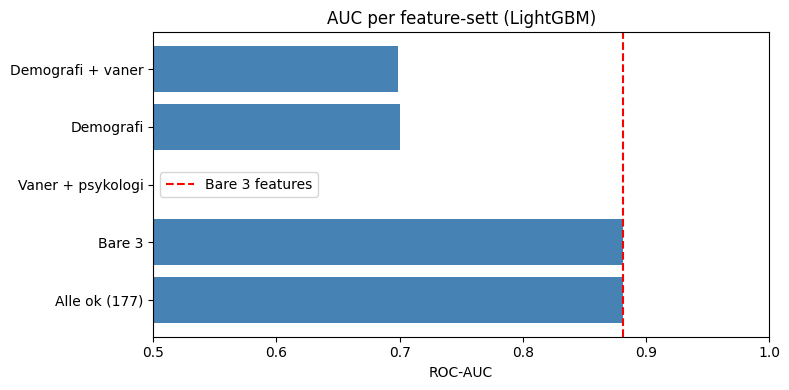

In [41]:
# Kolonner vi aldri skal bruke (direkte formuesutfall + metadata)
LEAKAGE = {
    'net_worth', 'net_worth_log', 'net_worth_percentile',
    'wealth_bracket', 'wealth_category',
    'total_assets', 'investment_assets', 'total_liabilities',
    'cash_savings', 'checking_savings', 'stocks_value', 'bonds_value',
    'real_estate_value', 'retirement_accounts', 'business_equity',
    'alternative_assets', 'vehicle_assets', 'other_assets',
    'mortgage_debt', 'student_debt', 'credit_card_debt', 'business_debt', 'other_debt',
    'monthly_income', 'monthly_expenses', 'monthly_savings', 'annual_savings',
    'portfolio_diversification_score', 'investment_income_ratio', 'passive_income_ratio',
    'financial_independence_status', 'multi_millionaire_status',
    'high_saver_status', 'high_investor_status', 'entrepreneur_status',
    'high_financial_literacy', 'high_productivity', 'high_debt_risk',
    'financial_stability_score', 'investment_rate',
    'housing_cost_ratio', 'luxury_spending_ratio', 'financial_buffer_months',
    'asset_diversification_score', 'income_diversification_score',
    'business_income_ratio', 'work_to_leisure_ratio', 'learning_to_work_ratio',
    'health_consistency_index', 'financial_discipline_index', 'wealth_building_index',
    'synthetic_person_id', 'dataset_version', 'generation_seed',
    'currency', 'exchange_rate_to_usd',
    'millionaire_status',
}

# Alle numeriske kolonner som ikke lekker
alle_ok = [c for c in df.select_dtypes(include='number').columns if c not in LEAKAGE]

# Vaner og psykologi (kategoriene I, K, L, P i dataordboken)
vaner_psyk = [c for c in [
    'daily_productivity_score', 'weekly_productivity_score', 'morning_routine_score',
    'evening_routine_score', 'daily_planning', 'weekly_planning', 'monthly_goal_review',
    'deep_work_hours_per_day', 'focused_work_sessions', 'distraction_frequency',
    'social_media_hours_per_day', 'screen_time_hours_per_day', 'task_completion_rate',
    'procrastination_score', 'time_management_score', 'priority_setting_score',
    'calendar_usage', 'to_do_list_usage',
    'exercise_days_per_week', 'strength_training_days', 'cardio_days',
    'walking_steps_per_day', 'water_intake_liters', 'sleep_quality_score',
    'stress_level', 'mindfulness_score', 'energy_level', 'health_routine_consistency',
    'sleep_duration_hours',
    'financial_discipline_score', 'self_control_score', 'delayed_gratification_score',
    'risk_tolerance_score', 'risk_aversion_score', 'confidence_score',
    'resilience_score', 'growth_mindset_score', 'long_term_orientation_score',
    'goal_orientation_score', 'consistency_score', 'adaptability_score',
    'decision_making_score', 'financial_anxiety_score', 'stress_management_score',
    'routine_consistency_score', 'saving_consistency_score', 'investment_consistency_score',
    'exercise_consistency_score', 'sleep_consistency_score', 'learning_consistency_score',
    'goal_consistency_score', 'budget_consistency_score', 'overall_habit_consistency_score',
    'habit_tracking',
] if c in df.columns]

demografi = ['age', 'education_years', 'years_of_experience', 'dependents_count', 'weekly_work_hours']

feature_sett = {
    f'Alle ok ({len(alle_ok)})': alle_ok,
    'Bare 3':               FEATURES,
    'Vaner + psykologi':    vaner_psyk,
    'Demografi':            demografi,
    'Demografi + vaner':    demografi + vaner_psyk,
}

# Tren LightGBM på hvert sett og noter AUC (kan ta ~30 sek)
print('Trener... (vennligst vent)\n')
auc_resultater = {}
for navn, cols in feature_sett.items():
    X_tr = df[cols + [TARGET]].dropna()
    y_fs = X_tr[TARGET]
    X_fs = X_tr[cols]
    Xtr, Xte, ytr, yte = train_test_split(X_fs, y_fs, test_size=0.2, stratify=y_fs, random_state=42)
    m = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
    m.fit(Xtr, ytr)
    auc = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
    auc_resultater[navn] = round(auc, 4)
    print(f'{navn:<30} AUC = {auc:.4f}')

# Diagram
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(list(auc_resultater.keys()), list(auc_resultater.values()), color='steelblue')
ax.set_xlim(0.5, 1.0)
ax.axvline(x=auc_resultater['Bare 3'], color='red', linestyle='--', label='Bare 3 features')
ax.set_xlabel('ROC-AUC')
ax.set_title('AUC per feature-sett (LightGBM)')
ax.legend()
plt.tight_layout()
plt.show()


## 4. Metrikkene for den endelige modellen

Vi ser nærmere på LightGBM med de 3 featurene. I tillegg til AUC og F1 sjekker vi om modellen er overtilpasset – det vil si om den gjør det mye bedre på treningsdata enn på testdata.

--- AUC: trening vs test ---
Trenings-AUC: 0.8938
Test-AUC:     0.8817
Differanse:   0.0121  (under 0,02 er bra)

--- Klassifikasjonsrapport ---
                precision    recall  f1-score   support

Ikke millionær       0.82      0.84      0.83     11502
     Millionær       0.77      0.75      0.76      8498

      accuracy                           0.80     20000
     macro avg       0.80      0.79      0.79     20000
  weighted avg       0.80      0.80      0.80     20000



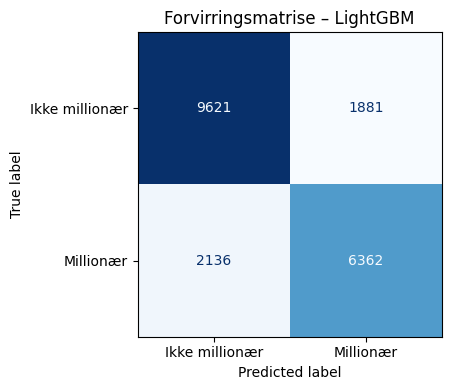


Riktig «ikke millionær»: 9,621
Feil «millionær»:        1,881  ← sa millionær, var det ikke
Feil «ikke millionær»:   2,136  ← sa ikke millionær, var det
Riktig «millionær»:      6,362


In [42]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Tren den endelige modellen
lgbm = LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)

y_pred  = lgbm.predict(X_test)
y_prob  = lgbm.predict_proba(X_test)[:, 1]
y_prob_train = lgbm.predict_proba(X_train)[:, 1]

auc_train = roc_auc_score(y_train, y_prob_train)
auc_test  = roc_auc_score(y_test,  y_prob)

print('--- AUC: trening vs test ---')
print(f'Trenings-AUC: {auc_train:.4f}')
print(f'Test-AUC:     {auc_test:.4f}')
print(f'Differanse:   {auc_train - auc_test:.4f}  (under 0,02 er bra)')

print()
print('--- Klassifikasjonsrapport ---')
print(classification_report(y_test, y_pred, target_names=['Ikke millionær', 'Millionær']))

# Forvirringsmatrise
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ikke millionær', 'Millionær'])
fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Forvirringsmatrise – LightGBM')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nRiktig «ikke millionær»: {tn:,}')
print(f'Feil «millionær»:        {fp:,}  ← sa millionær, var det ikke')
print(f'Feil «ikke millionær»:   {fn:,}  ← sa ikke millionær, var det')
print(f'Riktig «millionær»:      {tp:,}')


## 5. Gradient descent fra scratch

Gradient descent er optimeringsalgoritmen som brukes til å trene logistisk regresjon. Vi implementerer den i ren NumPy for å forstå hva som skjer under overflaten i sklearn.

Vi tester tre ulike learning rates og viser hvordan loss utvikler seg per epoke. Til slutt viser vi hva som skjer hvis vi glemmer å skalere dataene.

LR=0.01: slutt-loss=0.4974,  vekter=[0.376 0.713 0.444]
LR= 0.1: slutt-loss=0.4407,  vekter=[0.786 1.69  0.887]
LR= 1.0: slutt-loss=0.4405,  vekter=[0.811 1.768 0.913]


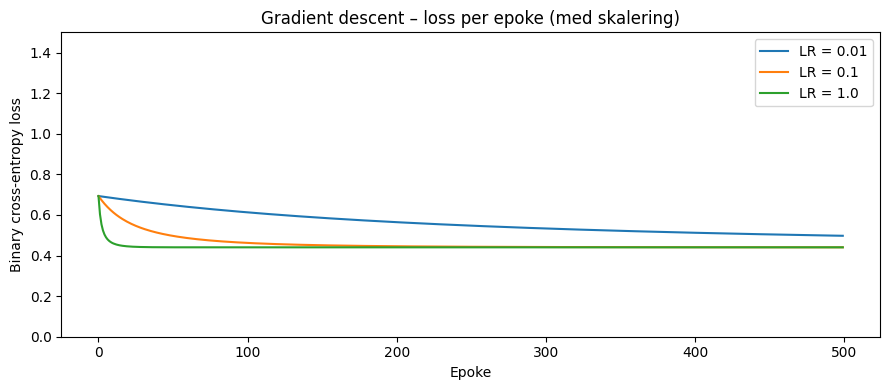


Sammenligning av vekter [age, income, savings_rate]:
  Scratch (LR=0.1): [0.786 1.69  0.887]
  Sklearn:          [0.811 1.768 0.913]

--- Uten skalering (LR=0.1, 50 epoker) ---
Loss etter  1 epoke:  0.6931
Loss etter 50 epoker: 19.8628

Med skalering konvergerer loss mot ~0.44.
Uten skalering er inntekt i hundretusener → gradienten for
income-vekten er ~100 000x større enn for age → modellen divergerer.


In [35]:
# --- Hjelpefunksjoner ---

def sigmoid(z):
    # np.clip hindrer overflow når z er veldig stor eller liten
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def bce_loss(y, y_hat):
    # Binary cross-entropy: straffer feil prediksjoner hardt
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

def gradient_descent(X, y, lr, n_epochs=500):
    n, p = X.shape
    w = np.zeros(p)   # start med alle vekter = 0
    b = 0.0
    losses = []
    for _ in range(n_epochs):
        y_hat = sigmoid(X @ w + b)          # fremoverpassering
        losses.append(bce_loss(y, y_hat))   # mål feilen
        dw = X.T @ (y_hat - y) / n         # gradient for vektene
        db = np.mean(y_hat - y)             # gradient for bias
        w -= lr * dw                        # oppdater ett steg
        b -= lr * db
    return w, b, losses

# --- Skaler data (kritisk for gradient descent) ---
scaler_gd = StandardScaler()
X_tr_sc = scaler_gd.fit_transform(X_train)
X_te_sc = scaler_gd.transform(X_test)
y_tr    = y_train.values

# --- Tren med tre learning rates ---
learning_rates = [0.01, 0.1, 1.0]
gd_resultater  = {}

for lr in learning_rates:
    w, b, losses = gradient_descent(X_tr_sc, y_tr, lr=lr, n_epochs=500)
    gd_resultater[lr] = (w, b, losses)
    print(f'LR={lr:4}: slutt-loss={losses[-1]:.4f},  vekter={np.round(w, 3)}')

# --- Plot loss-kurver ---
fig, ax = plt.subplots(figsize=(9, 4))
for lr, (_, _, losses) in gd_resultater.items():
    ax.plot(losses, label=f'LR = {lr}')
ax.set_xlabel('Epoke')
ax.set_ylabel('Binary cross-entropy loss')
ax.set_title('Gradient descent – loss per epoke (med skalering)')
ax.set_ylim(0, 1.5)
ax.legend()
plt.tight_layout()
plt.show()

# --- Sammenlign vekter med sklearn ---
lr_sk = LogisticRegression(max_iter=1000, random_state=42)
lr_sk.fit(X_tr_sc, y_tr)
w_scratch = gd_resultater[0.1][0]

print('\nSammenligning av vekter [age, income, savings_rate]:')
print(f'  Scratch (LR=0.1): {np.round(w_scratch, 3)}')
print(f'  Sklearn:          {np.round(lr_sk.coef_[0], 3)}')

# --- Vis hva som skjer UTEN skalering ---
print('\n--- Uten skalering (LR=0.1, 50 epoker) ---')
_, _, losses_ns = gradient_descent(X_train.values, y_tr, lr=0.1, n_epochs=50)
print(f'Loss etter  1 epoke:  {losses_ns[0]:.4f}')
print(f'Loss etter 50 epoker: {losses_ns[-1]:.4f}')
print()
print('Med skalering konvergerer loss mot ~0.44.')
print('Uten skalering er inntekt i hundretusener → gradienten for')
print('income-vekten er ~100 000x større enn for age → modellen divergerer.')


## 6. L1-regularisering

L1-regularisering legger til en straff i treningen som tvinger uviktige feature-vekter ned til nøyaktig 0. Det fungerer dermed som en automatisk feature-seleksjon.

Parameteren `C` styrer styrken: lav C gir sterk straff og færre features. Vi ser hvilke features som overlever ved ulike C-verdier.

C        Features ≠ 0     AUC     
----------------------------------
10       175              0.8767
1        171              0.8770
0.1      144              0.8783
0.01     13               0.8801
0.001    6                0.8695

Features som overlever ved C=0.001:
  income_percentile                        vekt=0.7
  savings_rate                             vekt=0.308
  years_of_experience                      vekt=0.199
  annual_salary                            vekt=0.076
  total_annual_income                      vekt=0.033
  age                                      vekt=0.032


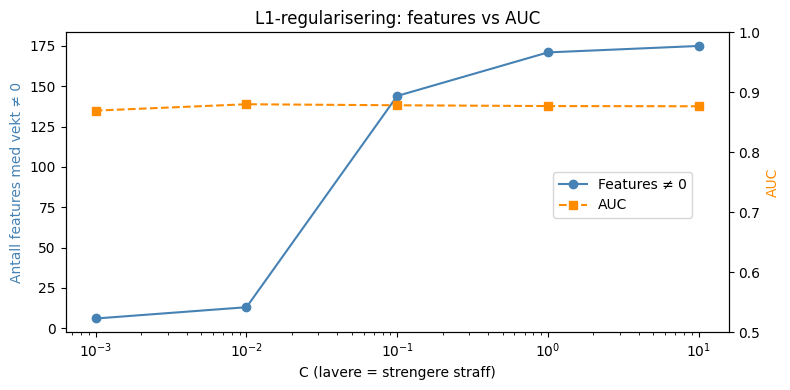

In [36]:
# Bygg datasett med alle ikke-lekkende numeriske kolonner
df_alle = df[alle_ok + [TARGET]].dropna()
X_alle  = df_alle[alle_ok]
y_alle  = df_alle[TARGET]

X_alle_tr, X_alle_te, y_alle_tr, y_alle_te = train_test_split(
    X_alle, y_alle, test_size=0.2, stratify=y_alle, random_state=42
)

sc_alle = StandardScaler()
X_alle_tr_sc = sc_alle.fit_transform(X_alle_tr)
X_alle_te_sc = sc_alle.transform(X_alle_te)

# Test flere C-verdier
C_verdier = [10, 1, 0.1, 0.01, 0.001]
l1_resultater = []

print(f'{"C":<8} {"Features ≠ 0":<16} {"AUC":<8}')
print('-' * 34)
for C in C_verdier:
    m = LogisticRegression(penalty='l1', solver='liblinear', C=C, max_iter=1000, random_state=42)
    m.fit(X_alle_tr_sc, y_alle_tr)
    n_nonzero = (m.coef_ != 0).sum()
    auc = roc_auc_score(y_alle_te, m.predict_proba(X_alle_te_sc)[:, 1])
    l1_resultater.append((C, n_nonzero, auc))
    print(f'{C:<8} {n_nonzero:<16} {auc:.4f}')

# Vis hvilke features som overlever ved C=0.001
m_streng = LogisticRegression(penalty='l1', solver='liblinear', C=0.001, max_iter=1000, random_state=42)
m_streng.fit(X_alle_tr_sc, y_alle_tr)
overlevende = [(feat, round(coef, 3))
               for feat, coef in zip(alle_ok, m_streng.coef_[0])
               if coef != 0]
print(f'\nFeatures som overlever ved C=0.001:')
for feat, coef in sorted(overlevende, key=lambda x: abs(x[1]), reverse=True):
    print(f'  {feat:<40} vekt={coef}')

# Plot: features vs AUC
fig, ax1 = plt.subplots(figsize=(8, 4))
c_vals   = [r[0] for r in l1_resultater]
nonzeros = [r[1] for r in l1_resultater]
aucs     = [r[2] for r in l1_resultater]

ax1.set_xscale('log')
ax1.plot(c_vals, nonzeros, 'o-', color='steelblue', label='Features ≠ 0')
ax1.set_xlabel('C (lavere = strengere straff)')
ax1.set_ylabel('Antall features med vekt ≠ 0', color='steelblue')
ax2 = ax1.twinx()
ax2.plot(c_vals, aucs, 's--', color='darkorange', label='AUC')
ax2.set_ylabel('AUC', color='darkorange')
ax2.set_ylim(0.5, 1.0)
ax1.set_title('L1-regularisering: features vs AUC')
fig.legend(loc='center right', bbox_to_anchor=(0.88, 0.5))
plt.tight_layout()
plt.show()


## 7. Beslutningsgrenser

En beslutningsgrense er linjen (eller kurven) som skiller "millionær" fra "ikke millionær" i feature-rommet.

Vi holder `total_annual_income` fast på medianen og varierer `age` og `savings_rate` over et rutenett.  
For hvert punkt i rutenettet ber vi modellen om sannsynligheten for "millionær" og farger punktet deretter.

Logistisk regresjon gir én rett linje siden modellen er lineær. Beslutningstreet lager trappetrinn fordi det splitter på faste terskelverdier. Random Forest jevner ut trappene siden den kombinerer mange trær.

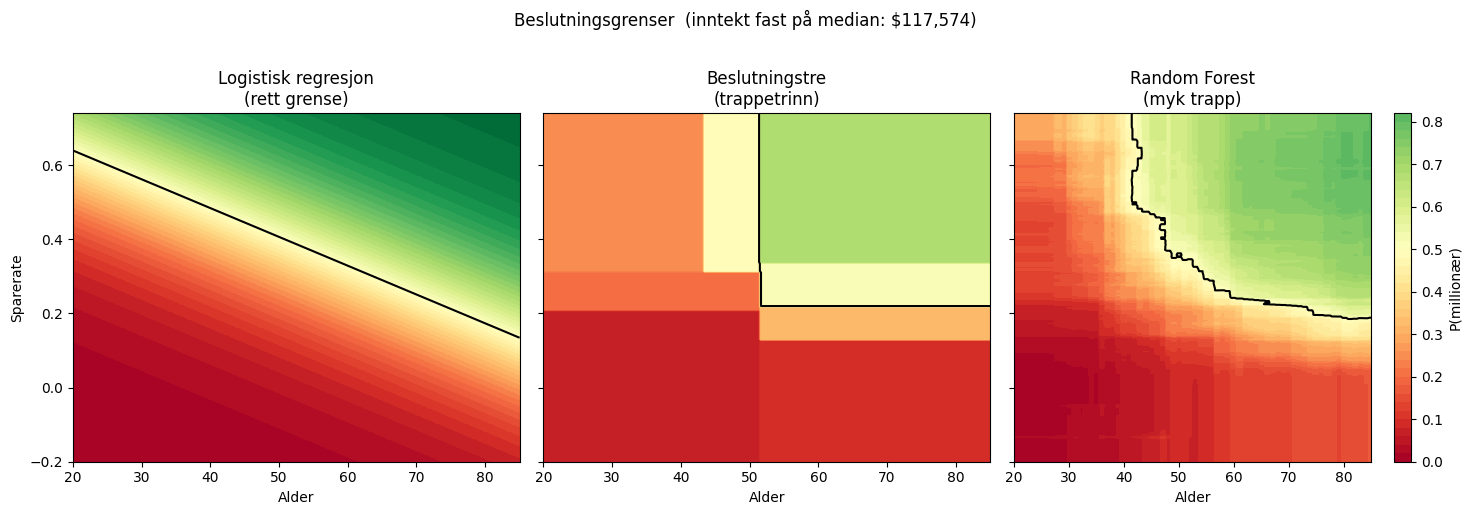

Den svarte linjen markerer 50 %-grensen.
Grønt = høy sannsynlighet for millionær, rødt = lav.


In [37]:
from sklearn.tree import DecisionTreeClassifier

# --- Lag rutenett ---
median_income = X_train['total_annual_income'].median()
age_range  = np.linspace(20, 85, 200)
rate_range = np.linspace(-0.2, 0.74, 200)
age_grid, rate_grid = np.meshgrid(age_range, rate_range)

grid = np.column_stack([
    age_grid.ravel(),
    np.full(age_grid.size, median_income),
    rate_grid.ravel(),
])
grid_df = pd.DataFrame(grid, columns=FEATURES)

# --- Tren de tre modellene ---
sc_gr = StandardScaler()
X_tr_sc2 = sc_gr.fit_transform(X_train)
grid_sc  = sc_gr.transform(grid_df)

logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_tr_sc2, y_train)

tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# --- Plot ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
modeller_gr = [
    ('Logistisk regresjon\n(rett grense)', logreg, grid_sc,  True),
    ('Beslutningstre\n(trappetrinn)',       tree,   grid_df,  False),
    ('Random Forest\n(myk trapp)',          rf,     grid_df,  False),
]

for ax, (tittel, modell, X_gr, er_skalert) in zip(axes, modeller_gr):
    probs = modell.predict_proba(X_gr)[:, 1].reshape(age_grid.shape)
    cf = ax.contourf(age_grid, rate_grid, probs, levels=50, cmap='RdYlGn', vmin=0, vmax=1)
    ax.contour(age_grid, rate_grid, probs, levels=[0.5], colors='black', linewidths=1.5)
    ax.set_xlabel('Alder')
    ax.set_title(tittel)

axes[0].set_ylabel('Sparerate')
fig.colorbar(cf, ax=axes[-1], label='P(millionær)')
fig.suptitle(f'Beslutningsgrenser  (inntekt fast på median: ${median_income:,.0f})', y=1.02)
plt.tight_layout()
plt.show()

print('Den svarte linjen markerer 50 %-grensen.')
print('Grønt = høy sannsynlighet for millionær, rødt = lav.')
